# RehaPiano, week 5 (short version): hand balance in two games, by 10-year age group

**Task (sheet column G):** evaluate the balance of hand forces also in the rhythm test, compare it with EXACT_FORCE, analyse it by age categories, and separate the effect of age from the effect of the illness.

This is a short, independent version of Maksym's `../rovnovaha_ruk.ipynb`. The main difference: **age is grouped in 10-year bins**, and the healthy group is the **76 questionnaire-screened controls** (as in weeks 2–3). The 14 other controls are left out of comparisons. Blue = healthy, orange = sick. "Sick" means recruited into the patient cohort; it is not a diagnosis.

**Balance of one person** = force of the weaker hand ÷ force of the stronger hand (1 = both hands equal, 0 = one hand does nothing).

| Game | What the player does | "Force of a hand" |
|---|---|---|
| EXACT_FORCE | holds a steady force with all fingers (4 × 16 s) | mean finger force of the hand, 3–15 s (week-3 pipeline) |
| RHYTHM | presses and releases repeatedly with both hands (4 × 31 s) | **force range** of the hand: 95th − 5th percentile of its mean finger force, 2–30 s |

One value per person: median over the attempts of a session, then mean over sessions.

In [1]:
import pandas as pd
from IPython.display import Image, Markdown, display

import week5_analysis as w5

R = w5.run()  # uses the cached per-attempt table; pass recompute=True to rebuild it from the raw recordings (~30 s)
pd.set_option("display.precision", 2)
figure = lambda name: display(Image(filename=str(w5.FIG / f"{name}.png")))
say = lambda text: display(Markdown(text))

## 1. Measuring balance in the rhythm test

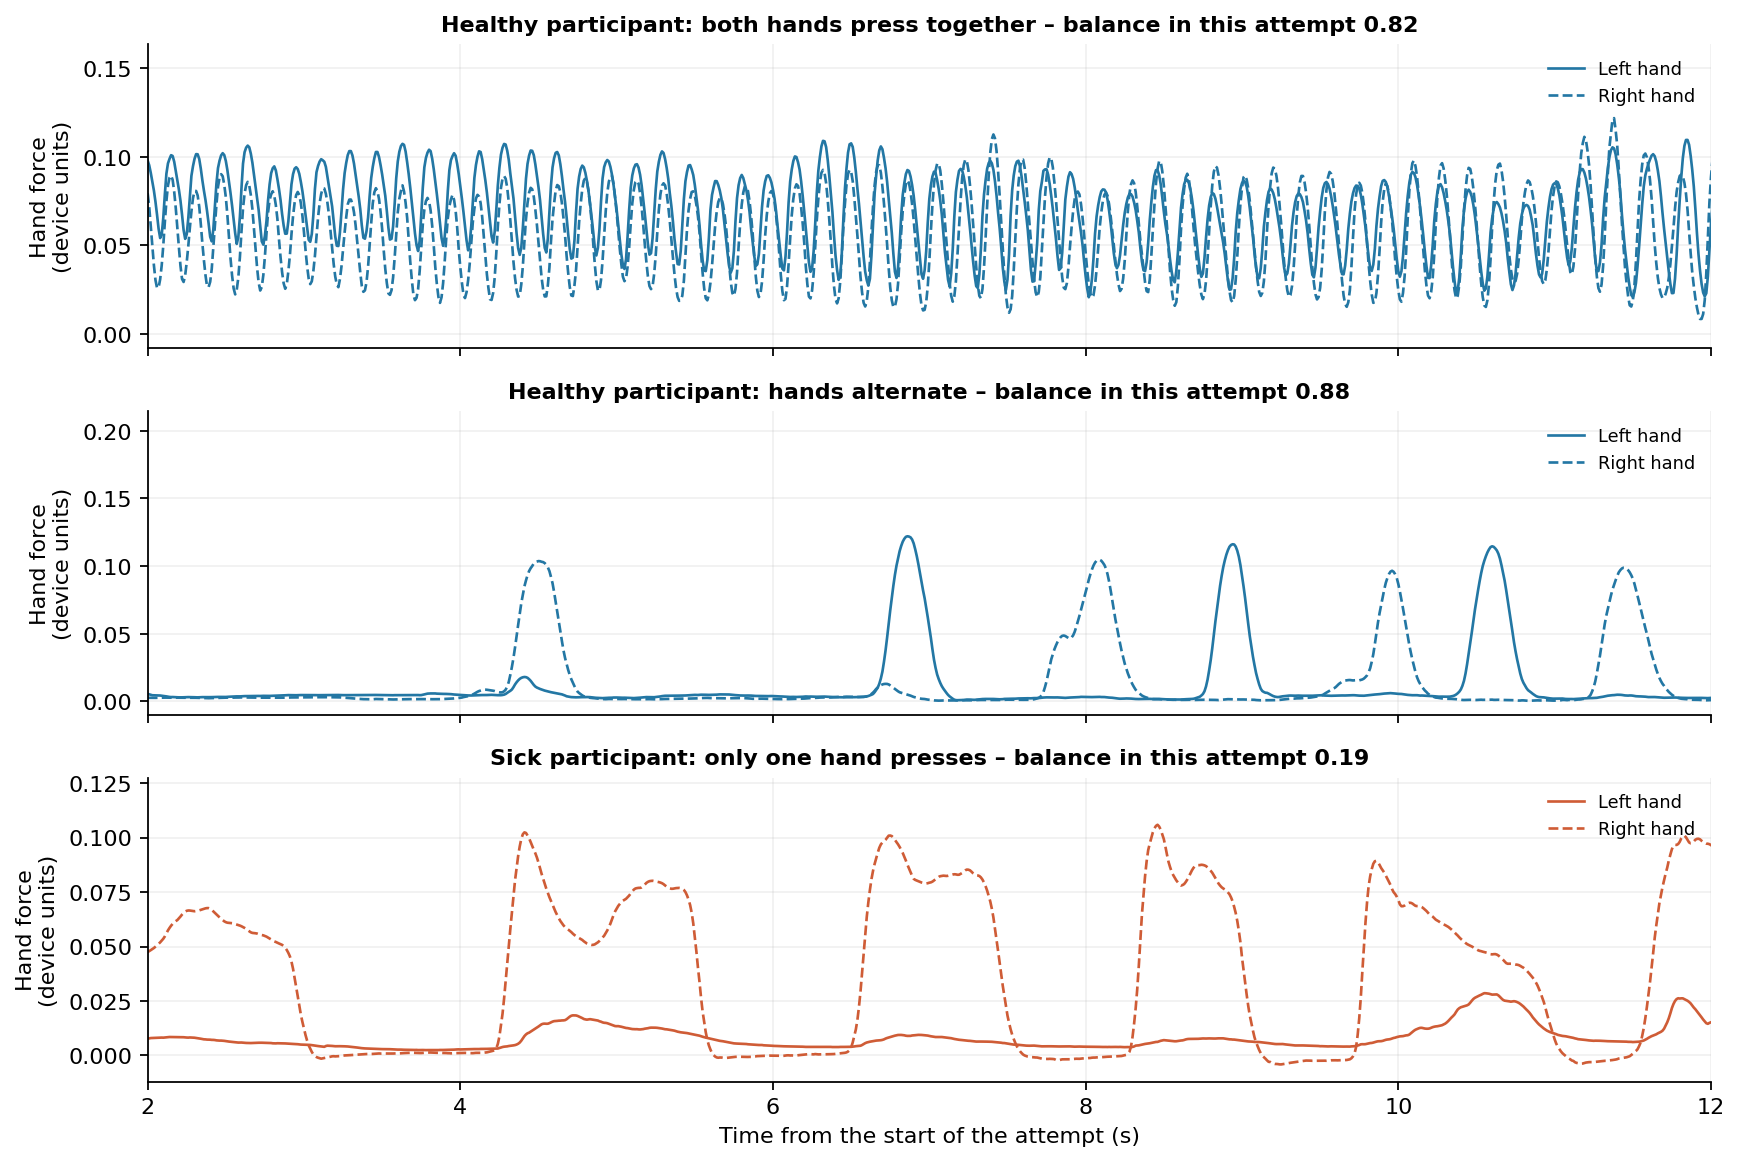

Most people press with both hands together (top), but some alternate hands (middle). The force range of each hand handles both styles and needs no press detection. A person who presses with only one hand (bottom) gets a balance close to 0. The rhythm recordings cover **138 people, 173 sessions and 692 attempts**, all usable; 27 recordings existed in several folders, and those copies were byte-identical.

In [2]:
figure("01_rhythm_examples")
c = R["checks"]
say(f"Most people press with both hands together (top), but some alternate hands (middle). The force range of each hand "
    f"handles both styles and needs no press detection. A person who presses with only one hand (bottom) gets a balance "
    f"close to 0. The rhythm recordings cover **{c['people_with_rhythm']} people, {c['rhythm_sessions']} sessions and "
    f"{c['rhythm_attempts']} attempts**, all usable; {c['files_with_copies']} recordings existed in several folders, and "
    f"those copies were byte-identical.")

In [3]:
display(R["maksym_comparison"].set_index("quantity"))
say(f"**Cross-check with Maksym's version.** Using his reference (all 90 controls), this simpler measure reproduces his "
    f"numbers: EXACT_FORCE is identical, and the rhythm test gives 16 instead of 18 weak-handed sick people. Person by "
    f"person, the force range and the press-amplitude measure agree closely (Spearman ρ = {c['rho_range_vs_press']:.2f}).")

,Maksym (press amplitude),this version (force range)
quantity,,
"rhythm median, healthy",0.87,0.88
"rhythm median, sick",0.70,0.75
"EXACT_FORCE median, healthy",0.94,0.94
"EXACT_FORCE median, sick",0.89,0.89
"weak hand in rhythm, sick",18.00,16.00
"weak hand in rhythm, healthy",3.00,3.00
"weak hand in EXACT_FORCE, sick",6.00,6.00
"weak hand in EXACT_FORCE, healthy",3.00,3.00


**Cross-check with Maksym's version.** Using his reference (all 90 controls), this simpler measure reproduces his numbers: EXACT_FORCE is identical, and the rhythm test gives 16 instead of 18 weak-handed sick people. Person by person, the force range and the press-amplitude measure agree closely (Spearman ρ = 0.90).

## 2. Balance in each 10-year age group

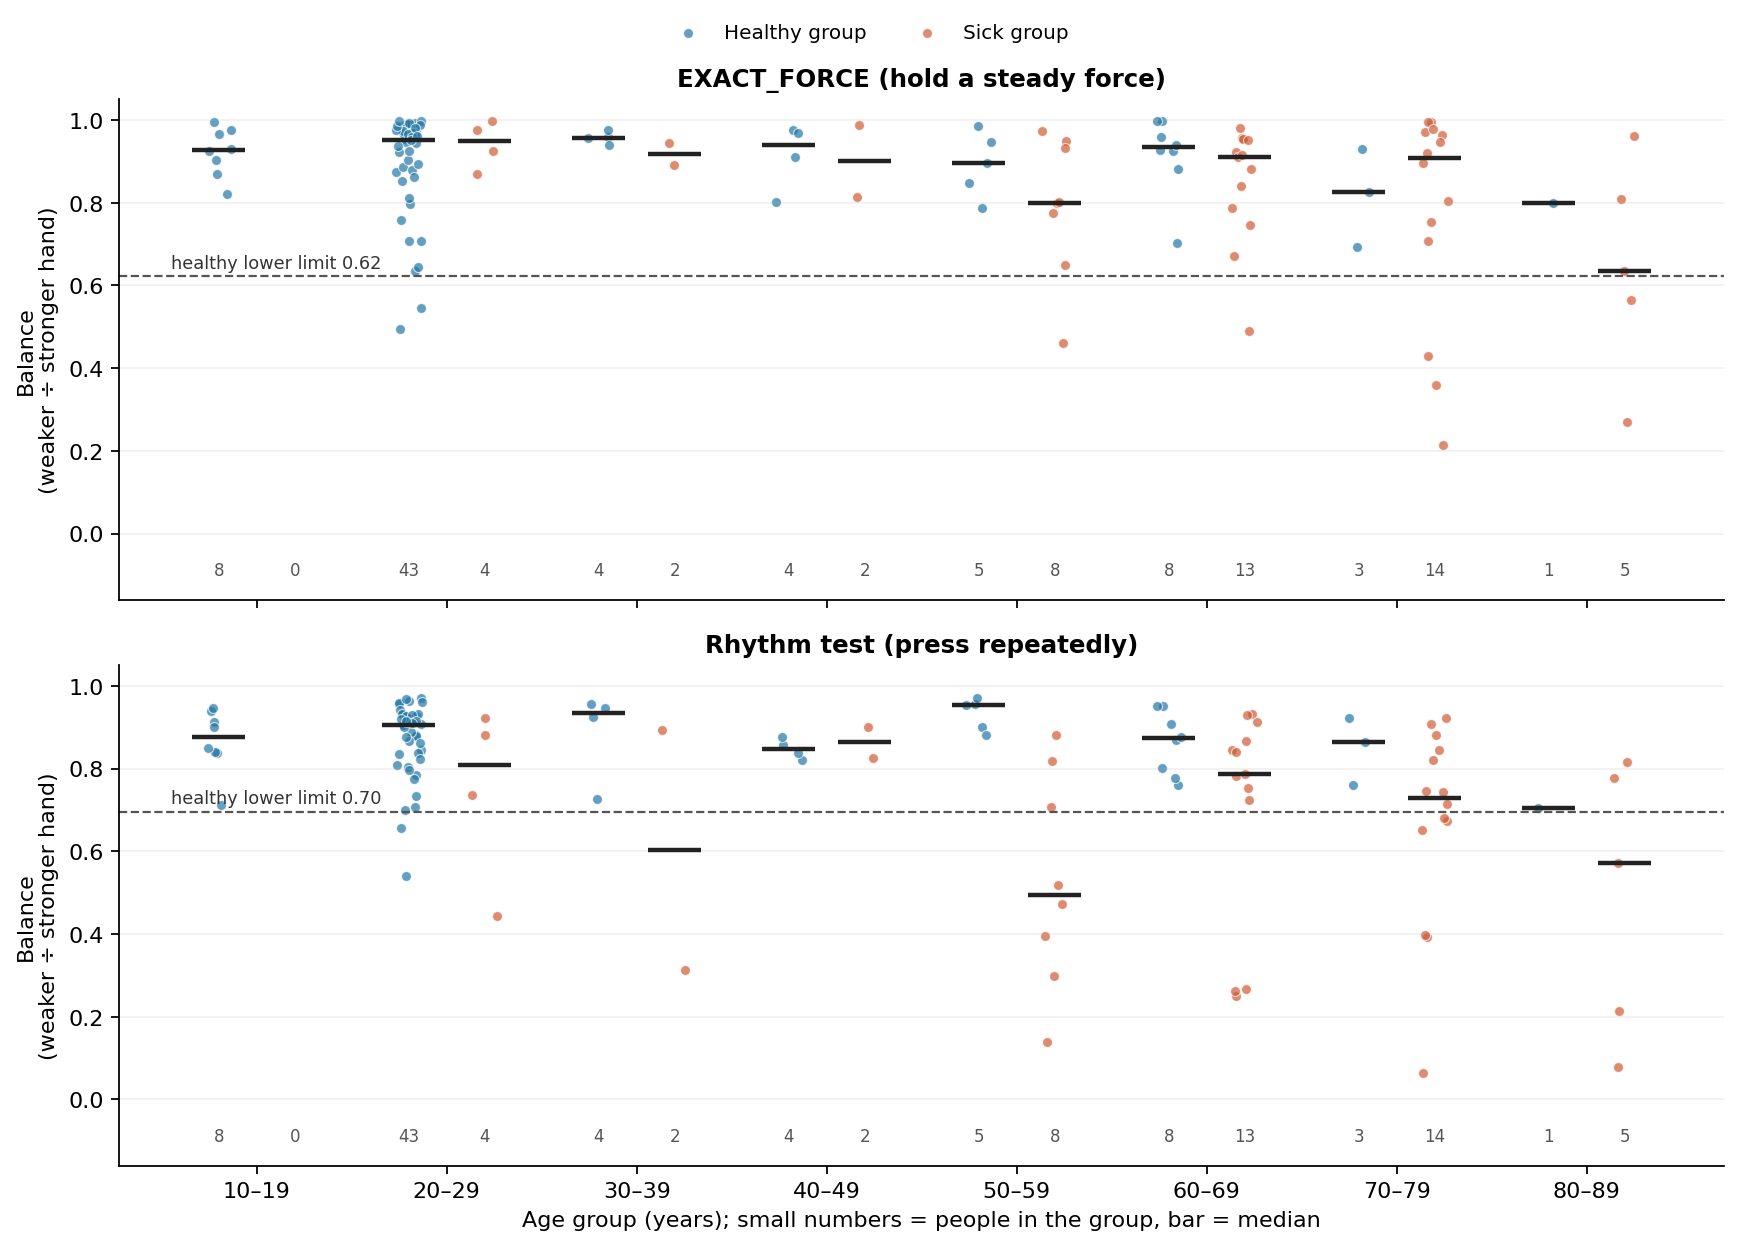

Each dot is one person; the bar is the group median. The dashed line is the **healthy lower limit**, the value below which only 2.5 % of the 76 healthy people fall: 0.62 in EXACT_FORCE and 0.70 in the rhythm test. The small numbers show how many people are in each group. Most 10-year groups are small, so medians of 1–5 people are only indicative.

Healthy n  Healthy median  Healthy below limit  Sick n  \
test        decade                                                           
EXACT_FORCE 10–19           8            0.93                    0       0   
            20–29          43            0.95                    2       4   
            30–39           4            0.96                    0       2   
            40–49           4            0.94                    0       2   
            50–59           5            0.90                    0       8   
            60–69           8            0.93                    0      13   
            70–79           3            0.83                    0      14   
            80–89           1            0.80                    0       5   
Rhythm      10–19           8            0.88                    0       0   
            20–29          43            0.91                    2       4   
            30–39           4            0.94                    0       2   
            40–49           4            0.85                    0       2   
            50–59           5            0.95                    0       8   
            60–69           8            0.87                    0      13   
            70–79           3            0.86                    0      14   
            80–89           1            0.71                    0       5   

                    Sick median  Sick below limit         p  p (Holm)  
test        decade                                                     
EXACT_FORCE 10–19           NaN                 0       NaN       NaN  
            20–29          0.95                 0  5.19e-01  1.00e+00  
            30–39          0.92                 0       NaN       NaN  
            40–49          0.90                 0       NaN       NaN  
            50–59          0.80                 1  3.54e-01  1.00e+00  
            60–69          0.91                 1  1.40e-01  5.61e-01  
            70–79          0.91                 3  6.76e-01  1.00e+00  
            80–89          0.63                 2       NaN       NaN  
Rhythm      10–19           NaN                 0       NaN       NaN  
            20–29          0.81                 1  2.25e-01  4.21e-01  
            30–39          0.60                 1       NaN       NaN  
            40–49          0.86                 0       NaN       NaN  
            50–59          0.49                 5  1.55e-03  6.22e-03  
            60–69          0.79                 3  1.40e-01  4.21e-01  
            70–79          0.73                 6  1.56e-01  4.21e-01  
            80–89          0.57                 3       NaN       NaN

p = Mann–Whitney test, only where both groups have at least 3 people; Holm-corrected within each game.

In [4]:
figure("02_balance_by_decade")
lim = R["limits"]
say(f"Each dot is one person; the bar is the group median. The dashed line is the **healthy lower limit**, the value "
    f"below which only 2.5 % of the 76 healthy people fall: {lim['exact_force_ratio']:.2f} in EXACT_FORCE and "
    f"{lim['rhythm_ratio']:.2f} in the rhythm test. The small numbers show how many people are in each group. Most "
    f"10-year groups are small, so medians of 1–5 people are only indicative.")
s = R["decade_summary"].copy()
s["test"] = s["test"].map({"exact_force_ratio": "EXACT_FORCE", "rhythm_ratio": "Rhythm"})
display(s.set_index(["test", "decade"]))
say("p = Mann–Whitney test, only where both groups have at least 3 people; Holm-corrected within each game.")

## 3. How many people have a weakly used hand, per age group

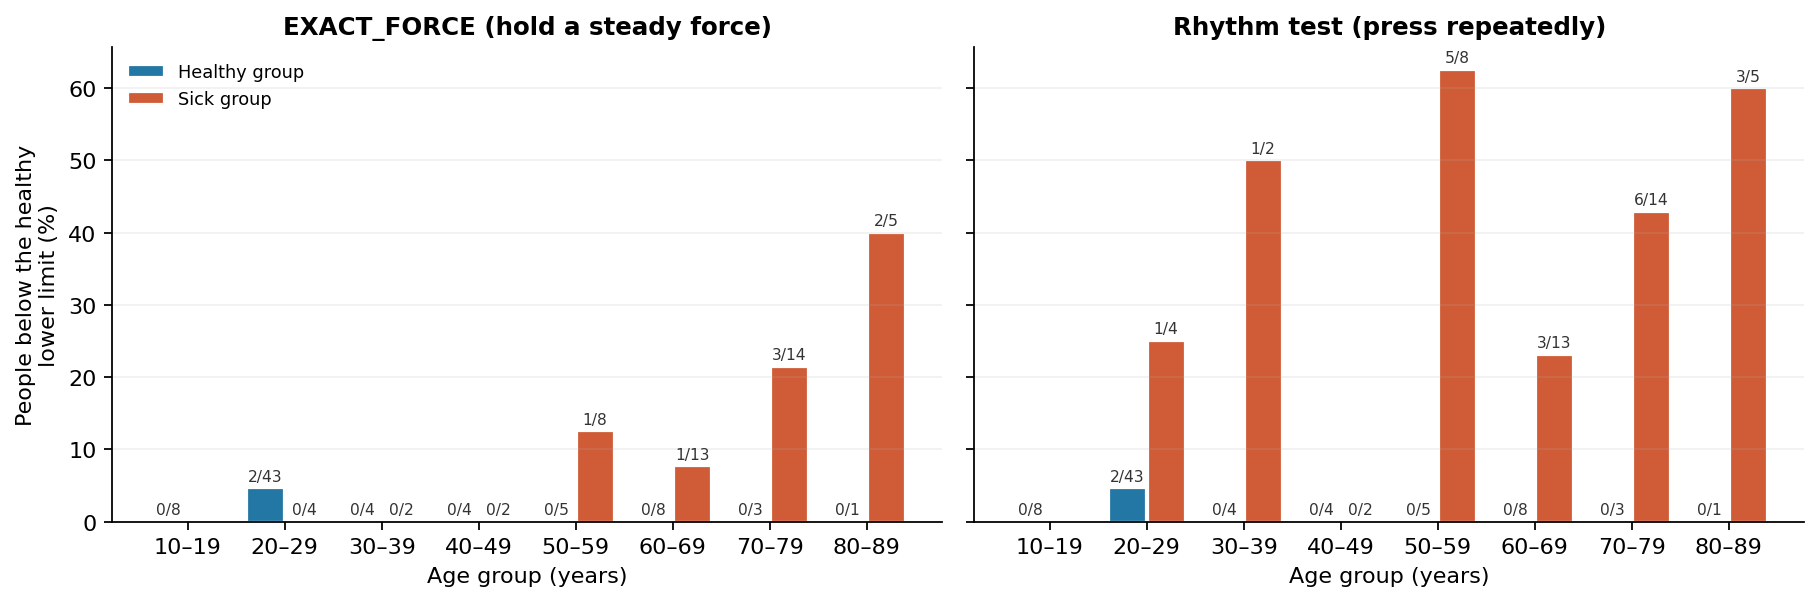

Below the healthy lower limit: **EXACT_FORCE 7 of 48 sick** vs 2 of 76 healthy; **rhythm test 19 of 48 sick** vs 2 of 76 healthy. The two healthy people below the limit are both in their twenties. In every age group from 30 up, no healthy person is below the limit, while weakly used hands appear among sick people in almost every age group, most often in the rhythm test.

In [5]:
figure("03_weak_hand_share_by_decade")
s = R["decade_summary"]
sick = s.groupby("test")[["Sick below limit", "Sick n"]].sum()
healthy = s.groupby("test")[["Healthy below limit", "Healthy n"]].sum()
say(f"Below the healthy lower limit: **EXACT_FORCE {int(sick.loc['exact_force_ratio', 'Sick below limit'])} of 48 sick** "
    f"vs {int(healthy.loc['exact_force_ratio', 'Healthy below limit'])} of 76 healthy; **rhythm test "
    f"{int(sick.loc['rhythm_ratio', 'Sick below limit'])} of 48 sick** vs {int(healthy.loc['rhythm_ratio', 'Healthy below limit'])} "
    f"of 76 healthy. The two healthy people below the limit are both in their twenties. In every age group from 30 up, "
    f"no healthy person is below the limit, while weakly used hands appear among sick people in almost every age group, "
    f"most often in the rhythm test.")

## 4. Age or illness?

In [6]:
a = R["age_effect_healthy"].copy()
a["test"] = a["test"].map({"exact_force_ratio": "EXACT_FORCE", "rhythm_ratio": "Rhythm"})
display(a.set_index("test"))
say("**Age alone (healthy people only):** balance does not change with age in either game. The correlation with age is "
    "close to 0, and healthy people under and over 50 have almost the same median. Getting older does not by itself make "
    "the hands less balanced.")

,people,spearman_rho_age,p,median_under_50,median_50_plus,p_under_50_vs_50_plus
test,,,,,,
EXACT_FORCE,76,-0.07,0.57,0.95,0.92,0.23
Rhythm,76,0.04,0.73,0.90,0.88,0.94


**Age alone (healthy people only):** balance does not change with age in either game. The correlation with age is close to 0, and healthy people under and over 50 have almost the same median. Getting older does not by itself make the hands less balanced.

In [7]:
d = R["stratified_disease_effect"].copy()
d["test"] = d["test"].map({"exact_force_ratio": "EXACT_FORCE", "rhythm_ratio": "Rhythm"})
display(d.set_index("test"))
r = d.set_index("test")
say(f"**Illness at the same age.** Sick and healthy people are compared only within the same 10-year group, and the "
    f"group differences are pooled (decades with more people in both groups count more). The p-value comes from "
    f"shuffling the healthy/sick labels *only inside each decade* {w5.PERMUTATIONS:,} times, so age cannot create the "
    f"difference. In the **rhythm test** sick people have a **{abs(r.loc['Rhythm', 'sick_minus_healthy']):.2f} lower "
    f"balance** than healthy people of the same decade (p = {r.loc['Rhythm', 'p_permutation']:.4f}). In **EXACT_FORCE** "
    f"the difference is only {abs(r.loc['EXACT_FORCE', 'sick_minus_healthy']):.2f} and not significant "
    f"(p = {r.loc['EXACT_FORCE', 'p_permutation']:.2f}). Of the single decades, only 50–59 is significant on its own "
    f"after correction (rhythm, p Holm = 0.006); the others are too small.")

,decades_used,healthy_n,sick_n,sick_minus_healthy,p_permutation
test,,,,,
EXACT_FORCE,"20–29, 30–39, 40–49, 50–59, 60–69, 70–79, 80–89",68,48,-0.04,2.38e-01
Rhythm,"20–29, 30–39, 40–49, 50–59, 60–69, 70–79, 80–89",68,48,-0.19,1.00e-04


**Illness at the same age.** Sick and healthy people are compared only within the same 10-year group, and the group differences are pooled (decades with more people in both groups count more). The p-value comes from shuffling the healthy/sick labels *only inside each decade* 10,000 times, so age cannot create the difference. In the **rhythm test** sick people have a **0.19 lower balance** than healthy people of the same decade (p = 0.0001). In **EXACT_FORCE** the difference is only 0.04 and not significant (p = 0.24). Of the single decades, only 50–59 is significant on its own after correction (rhythm, p Holm = 0.006); the others are too small.

## Summary

In [8]:
c, d = R["checks"], R["stratified_disease_effect"].set_index("test")
s = R["decade_summary"].groupby("test")["Sick below limit"].sum()
say(f'''
| Question | Answer |
|---|---|
| Balance in the rhythm test | Healthy people stay balanced at every age; many sick people press clearly less with one hand. {int(s['rhythm_ratio'])} of 48 sick people are below the healthy lower limit, against {int(s['exact_force_ratio'])} in EXACT_FORCE. |
| Rhythm vs EXACT_FORCE | The tests agree only partly (ρ = {c['rho_tests_sick']:.2f} among sick people). The hand that presses less is the same in both games for {c['same_weaker_hand']:.0%} of all sick people (including those with almost balanced hands, where the weaker side is close to chance). The rhythm test separates the groups much more clearly. |
| 10-year age groups | Healthy medians are 0.83–0.96 in every age group from 10 to 79, in both games. Sick medians drop to about 0.5–0.8 from age 50 onwards (rhythm). |
| Age vs illness | Age alone does not change balance (healthy ρ ≈ 0). At the same age, illness lowers rhythm balance by {abs(d.loc['rhythm_ratio', 'sick_minus_healthy']):.2f} (p = {d.loc['rhythm_ratio', 'p_permutation']:.4f}); in EXACT_FORCE the effect is small ({abs(d.loc['exact_force_ratio', 'sick_minus_healthy']):.2f}) and not significant. |
''')


| Question | Answer |
|---|---|
| Balance in the rhythm test | Healthy people stay balanced at every age; many sick people press clearly less with one hand. 19 of 48 sick people are below the healthy lower limit, against 7 in EXACT_FORCE. |
| Rhythm vs EXACT_FORCE | The tests agree only partly (ρ = 0.46 among sick people). The hand that presses less is the same in both games for 73% of all sick people (including those with almost balanced hands, where the weaker side is close to chance). The rhythm test separates the groups much more clearly. |
| 10-year age groups | Healthy medians are 0.83–0.96 in every age group from 10 to 79, in both games. Sick medians drop to about 0.5–0.8 from age 50 onwards (rhythm). |
| Age vs illness | Age alone does not change balance (healthy ρ ≈ 0). At the same age, illness lowers rhythm balance by 0.19 (p = 0.0001); in EXACT_FORCE the effect is small (0.04) and not significant. |


### Limitations
- **Small age groups.** Several 10-year groups have only 1–5 healthy or sick people (the 70–79 and 80–89 healthy groups have 3 and 1). That is why the pooled within-decade test, not the single-decade tests, carries the conclusion.
- **Different game settings.** Healthy and sick people played the rhythm game with a different step setting, and sick people press more slowly (median about 1.5 vs 2.9 presses per second). A slower, effortful press could make one-sided weakness easier to see, so part of the gap may come from the setting rather than the illness.
- **Unknown handedness.** Handedness is not recorded for sick people, so "weaker hand" only means the hand that presses less, not necessarily the affected hand.
- **Labels.** Healthy is questionnaire-screened; diagnoses of the sick group are not available.